평가 기준은 [평가 기준 문서](docs/evaluation_criteria.md)를 참고하세요.

현재는 가짜 데이터 6장으로 코드의 작동을 확인하며,
출력된 점수는 실제 모델 성능이 아닙니다.

## 1. 라이브러리 및 라벨 규칙

In [2]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
)

# 소견 순서
FINDINGS = ["Cardiomegaly", "Edema", "Pleural Effusion"]
FINDING_NAMES = ["심비대", "폐부종", "흉수"]

# 클래스 순서
CLASS_NAMES = ["음성", "양성", "불확실"]
CLASS_LABELS = [0, 1, 2]

## 2. 평가 코드 검증용 가짜 데이터

In [3]:
y_true = np.array([
    [1, 0, 2],
    [0, 0, 1],
    [2, 1, 2],
    [0, 0, 0],
    [1, 1, 0],
    [1, 1, 1]
])

y_prob = np.array([
    [
        [0.10, 0.80, 0.10],  # 심비대: 음성, 양성, 불확실 확률
        [0.85, 0.10, 0.05],  # 폐부종: 음성, 양성, 불확실 확률
        [0.20, 0.25, 0.55],  # 흉수:   음성, 양성, 불확실 확률
    ],

    [
        [0.80, 0.15, 0.05],  # 심비대
        [0.10, 0.75, 0.15],  # 폐부종
        [0.10, 0.20, 0.70],  # 흉수
    ],

    [
        [0.30, 0.55, 0.15],
        [0.25, 0.40, 0.35],
        [0.05, 0.25, 0.70]
    ],

    [
        [0.80, 0.15, 0.05],
        [0.75, 0.20, 0.05],
        [0.90, 0.05, 0.05],
    ],

    [
        [0.10, 0.80, 0.10],
        [0.15, 0.75, 0.10],
        [0.80, 0.15, 0.05],
    ],

    [
        [0.10, 0.85, 0.05],
        [0.70, 0.20, 0.10],
        [0.15, 0.75, 0.10],
    ],
])

# 각 소견에서 가장 높은 확률의 클래스 선택
y_pred = np.argmax(y_prob, axis=2)

print(y_pred)

[[1 0 2]
 [0 1 2]
 [1 1 2]
 [0 0 0]
 [1 1 0]
 [1 0 1]]


## 3. 입력 데이터 검증

In [6]:
# 데이터 형태 확인
print("정답 형태:", y_true.shape)
print("예측 확률 형태:", y_prob.shape)
print("예측 코드 형태:", y_pred.shape)

# 정답과 예측 확률의 형태 확인
assert y_true.ndim == 2 and y_true.shape[1] == 3
assert y_prob.shape == (len(y_true), 3, 3)
assert y_pred.shape == y_true.shape

# 정답 코드가 0, 1, 2인지 확인
assert np.isin(y_true, [0, 1, 2]).all()

# 확률이 유효한지 확인
assert np.isfinite(y_prob).all()
assert ((y_prob >= 0) & (y_prob <= 1)).all()
assert np.allclose(y_prob.sum(axis=2), 1)

정답 형태: (6, 3)
예측 확률 형태: (6, 3, 3)
예측 코드 형태: (6, 3)


## 4. 소견별 성능 평가

In [7]:
for i, finding in enumerate(FINDING_NAMES):
    print(f"\n===== {finding} =====")

    print(classification_report(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        zero_division=0
    ))


===== 심비대 =====
              precision    recall  f1-score   support

          음성       1.00      1.00      1.00         2
          양성       0.75      1.00      0.86         3
         불확실       0.00      0.00      0.00         1

    accuracy                           0.83         6
   macro avg       0.58      0.67      0.62         6
weighted avg       0.71      0.83      0.76         6


===== 폐부종 =====
              precision    recall  f1-score   support

          음성       0.67      0.67      0.67         3
          양성       0.67      0.67      0.67         3
         불확실       0.00      0.00      0.00         0

    accuracy                           0.67         6
   macro avg       0.44      0.44      0.44         6
weighted avg       0.67      0.67      0.67         6


===== 흉수 =====
              precision    recall  f1-score   support

          음성       1.00      1.00      1.00         2
          양성       1.00      0.50      0.67         2
         불확실       0.67  

In [8]:
for i, finding in enumerate(FINDING_NAMES):
    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS
    )

    cm_df = pd.DataFrame(
        cm,
        index=[f"실제 {name}" for name in CLASS_NAMES],
        columns=[f"예측 {name}" for name in CLASS_NAMES]
    )

    print(f"===== {finding} 혼동행렬 =====")
    display(cm_df)

===== 심비대 혼동행렬 =====


,예측 음성,예측 양성,예측 불확실
실제 음성,2,0,0
실제 양성,0,3,0
실제 불확실,0,1,0


===== 폐부종 혼동행렬 =====


,예측 음성,예측 양성,예측 불확실
실제 음성,2,1,0
실제 양성,1,2,0
실제 불확실,0,0,0


===== 흉수 혼동행렬 =====


,예측 음성,예측 양성,예측 불확실
실제 음성,2,0,0
실제 양성,0,1,1
실제 불확실,0,0,2


In [9]:
# AUROC 평가

auroc_results = []

for i, finding in enumerate(FINDING_NAMES):
    # 해당 소견의 정답이 음성 또는 양성인 이미지 선택
    mask = np.isin(y_true[:, i], [0, 1])

    true_binary = y_true[mask, i]
    positive_prob = y_prob[mask, i, 1]

    # 음성과 양성이 모두 있어야 AUROC 계산 가능
    if len(np.unique(true_binary)) == 2:
        auroc = roc_auc_score(true_binary, positive_prob)
    else:
        auroc = np.nan

    auroc_results.append({
        "소견": finding,
        "평가 이미지 수": int(mask.sum()),
        "음성 수": int((true_binary == 0).sum()),
        "양성 수": int((true_binary == 1).sum()),
        "양성 AUROC": auroc
    })

auroc_df = pd.DataFrame(auroc_results)
display(auroc_df)

,소견,평가 이미지 수,음성 수,양성 수,양성 AUROC
0,심비대,5,2,3,1.000000
1,폐부종,6,3,3,0.666667
2,흉수,4,2,2,1.000000


## 5. 단일·복합 소견별 성능 비교

In [10]:
# 복합 소견별 성능 비교

# 세 소견 중 불확실 정답이 없는 이미지
certain_mask = (y_true != 2).all(axis=1)

# 이미지별 실제 양성 소견 개수
positive_count = (y_true ==1). sum(axis=1)

groups = {
    "양성 소견 0개": certain_mask & (positive_count == 0),
    "단일 소견 (양성 1개)": certain_mask & (positive_count == 1),
    "복합 소견 (양성 2~3개)": certain_mask & (positive_count >=2),
}

group_results = []

for group_name, mask in groups.items():
    n = int(mask.sum())

    if n>0:
        # 이미지마다 세 소견을 모두 맞혔는지 확인
        exact_match = (
            y_true[mask] == y_pred[mask]
        ).all(axis=1).mean()

        # 전체 소견 판단 중 맞힌 비율
        finding_accuracy = (
            y_true[mask] == y_pred[mask]
        ).mean()
    else:
        exact_match = np.nan
        finding_accuracy = np.nan

    group_results.append({
        "그룹": group_name,
        "이미지 수": n,
        "세 소견 모두 정답 비율": exact_match,
        "소견별 판단 정확도": finding_accuracy,
    })

group_df = pd.DataFrame(group_results)
display(group_df)

,그룹,이미지 수,세 소견 모두 정답 비율,소견별 판단 정확도
0,양성 소견 0개,1,1.0,1.000000
1,단일 소견 (양성 1개),1,0.0,0.333333
2,복합 소견 (양성 2~3개),2,0.5,0.833333


## 6. 결과 시각화

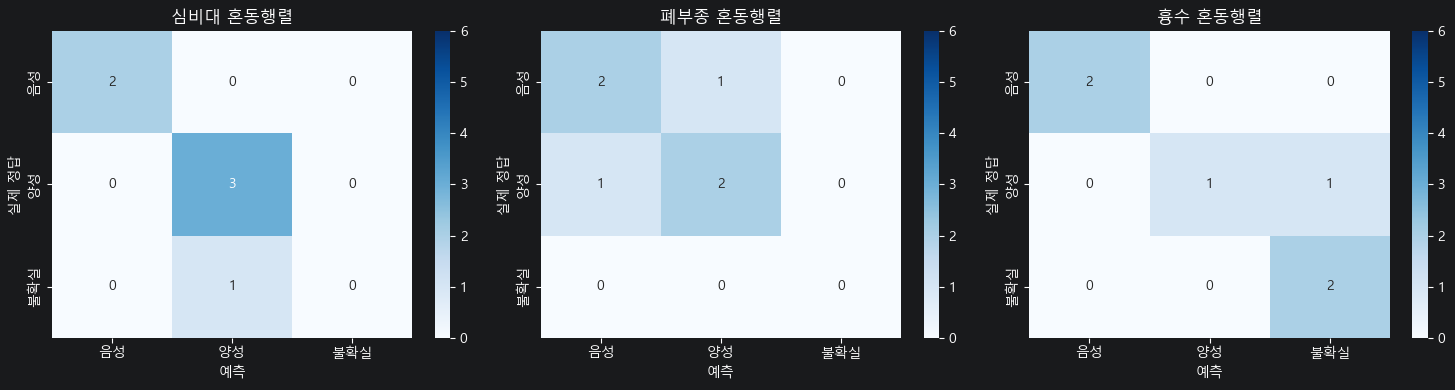

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Windows 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, finding in enumerate(FINDING_NAMES):
    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=CLASS_LABELS
    )

    sns.heatmap(
        cm,
        annot=True,             # 칸 안에 숫자 표시
        fmt="d",                # 정수로 표시
        cmap="Blues",           # 숫자가 클수록 진한 파란색
        vmin=0,
        vmax=len(y_true),       # 세 그래프의 색 기준 통일
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=axes[i]
    )

    axes[i].set_title(f"{finding} 혼동행렬")
    axes[i].set_xlabel("예측")
    axes[i].set_ylabel("실제 정답")

plt.tight_layout()
plt.show()

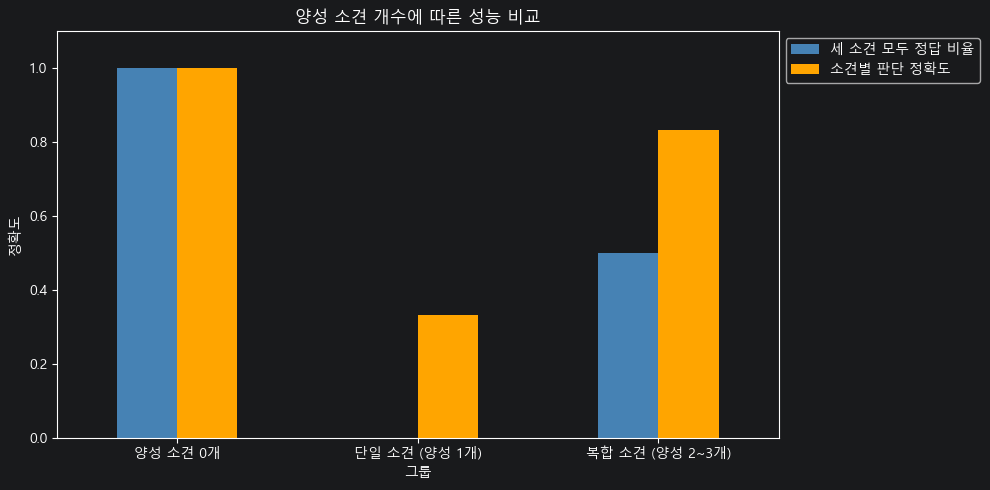

In [12]:
ax = group_df.plot(
    x="그룹",
    y=["세 소견 모두 정답 비율", "소견별 판단 정확도"],
    kind="bar",
    figsize=(10, 5),
    rot=0,
    color=["steelblue", "orange"]
)

ax.set_title("양성 소견 개수에 따른 성능 비교")
ax.set_xlabel("그룹")
ax.set_ylabel("정확도")
ax.set_ylim(0, 1.1)

ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

## 7. 오분류 사례 분석

In [17]:
error_results = []

for image_idx in range(len(y_true)):
    for finding_idx, finding in enumerate(FINDING_NAMES):
        true_label = int(y_true[image_idx, finding_idx])
        pred_label = int(y_pred[image_idx, finding_idx])

        # 정답과 예측이 다른 경우만 기록
        if true_label != pred_label:
            error_results.append({
                "이미지 번호": image_idx + 1,
                "소견": finding,
                "실제 정답": CLASS_NAMES[true_label],
                "모델 예측": CLASS_NAMES[pred_label],
                "예측 클래스 확률": y_prob[
                    image_idx, finding_idx, pred_label
                ],
            })

error_df = pd.DataFrame(
    error_results,
    columns=[
        "이미지 번호", "소견", "실제 정답",
        "모델 예측", "예측 클래스 확률"
    ]
)

display(error_df)

,이미지 번호,소견,실제 정답,모델 예측,예측 클래스 확률
0,2,폐부종,음성,양성,0.75
1,2,흉수,양성,불확실,0.70
2,3,심비대,불확실,양성,0.55
3,6,폐부종,양성,음성,0.70


In [21]:
# 1. 소견별 오분류 개수
error_counts = (
    error_df.groupby("소견")
    .size()
    .reindex(FINDING_NAMES, fill_value=0)
    .rename("오분류 개수")
)

print("===== 소견별 오분류 개수 =====")
print(error_counts.to_string())

# 2. 소견별 오류 유형
error_types = (
    error_df.groupby(["소견", "실제 정답", "모델 예측"])
    .size()
    .reset_index(name="개수")
)

print("\n===== 소견별 오류 유형 =====")
print(error_types.to_string(index=False))

===== 소견별 오분류 개수 =====
소견
심비대    1
폐부종    2
흉수     1

===== 소견별 오류 유형 =====
 소견 실제 정답 모델 예측  개수
심비대   불확실    양성   1
폐부종    양성    음성   1
폐부종    음성    양성   1
 흉수    양성   불확실   1
